<div style="display:flex; align-items:center; gap:18px; text-align:left">
  <img src="https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/assets/logo_ust.png" width="100">
  <div>
    <p>Diplomado en Inteligencia Artificial para los Negocios</p>
    <p>Facultad de Ingeniería y Negocios</p>
    <p>Módulo 2: Fundamentos de Machine Learning y herramientas Low Code</p>
    <p>Repaso en vivo · Clases 2 a 6 (solución)</p>
  </div>
</div>

# Repaso en vivo · Un problema de regresión de punta a punta

**El caso.** Una tienda (ficticia) lanza campañas de marketing todos los meses y guarda cuánto vendió
cada una. Antes de aprobar las campañas del próximo trimestre, la gerencia pregunta: **¿cuánto va a
vender esta campaña?** Es un problema de **regresión**: predecir un número, `ventas_mm` (millones de
pesos).

Hoy recorremos el flujo completo, una sola vez y sin atajos:

| Paso | Qué hacemos | Clase donde lo vimos |
|:--|:--|:--:|
| 1 | Cargar los datos | 2 |
| 2 | Análisis exploratorio (EDA) con *profiling* | 2 |
| 3 | Seleccionar variables: por criterio y con evidencia | 2 y 6 |
| 4 | Crear el experimento | 3 |
| 5 | Comparar modelos (*benchmark*) | 3 |
| 6 | Afinar el mejor (*tuning*) | 6 |
| 7 | Comparar el modelo base contra el tuneado | 6 |
| 8 | Validar contra el *holdout* (conjunto de prueba) | 3 y 6 |
| 9 | Explicar el modelo con SHAP | 6 |
| 10 | Guardar el modelo | 6 |
| 11 | Usarlo para decidir las campañas nuevas | — |

El foco no es el código (son pocas líneas por paso), sino **las decisiones** que tomamos entre un paso
y el siguiente.

## Preparación del entorno

Instalamos las librerías y dejamos listas las importaciones. La salida de la instalación queda oculta.

In [1]:
%%capture
!pip install -q pycaret==4.0.0a8 fg-data-profiling plotly ipywidgets shap "setuptools<81"

In [2]:
%matplotlib inline
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import plotly.express as px

# en Colab los datos se leen del repo público; en local, desde ../datasets/
REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-fundamentos-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

## Paso 1 · Cargar los datos

Cada fila es una **campaña ya terminada**. Las columnas:

| Columna | Qué es |
|:--|:--|
| `id_campana` | Código interno de la campaña |
| `mes` | Mes de lanzamiento (1 a 12) |
| `canal` | Redes sociales, Buscadores, Email o TV y radio |
| `presupuesto_mm` | Inversión en la campaña (millones de pesos) |
| `duracion_dias` | Días que estuvo activa |
| `descuento_pct` | Descuento ofrecido (%) |
| `dia_lanzamiento` | Día de la semana en que partió |
| `num_creatividades` | Cantidad de piezas gráficas distintas |
| `clics_mil` | Clics que recibió la campaña (miles) |
| `ventas_mm` | **Target**: ventas que generó (millones de pesos) |

In [3]:
campanas = pd.read_csv(BASE + 'campanas.csv')
print('Filas y columnas:', campanas.shape)
campanas.head()

Filas y columnas: (900, 10)


,id_campana,mes,canal,presupuesto_mm,duracion_dias,descuento_pct,dia_lanzamiento,num_creatividades,clics_mil,ventas_mm
0,CMP-0001,4,Email,8.4,28.0,0,viernes,7,28.5,11.8
1,CMP-0002,6,Buscadores,11.7,45.0,0,miércoles,2,56.2,25.4
2,CMP-0003,10,TV y radio,22.7,38.0,0,viernes,6,69.4,32.1
3,CMP-0004,9,Email,6.6,24.0,20,viernes,3,43.0,18.3
4,CMP-0005,10,Redes sociales,18.5,7.0,0,domingo,7,34.0,14.9


## Paso 2 · Análisis exploratorio (EDA)

Antes de modelar, miramos los datos con un **perfil automático** (*profiling*), como en la Clase 2: un
informe que revisa cada columna, los faltantes y las correlaciones. Buscamos tres cosas: **problemas de
calidad**, **la forma del target** y **qué variables parecen relacionarse con las ventas**.

In [ ]:
from data_profiling import ProfileReport

perfil = ProfileReport(campanas, title='Campañas de marketing — perfil de datos')
perfil.to_notebook_iframe()

**Qué mirar en el perfil:**

- **Alertas** (pestaña *Alerts*). Tres avisos importan hoy:
  - `duracion_dias` tiene **18 faltantes (2 %)**. Son pocos, así que no descartamos filas: PyCaret los
    completará (imputará) dentro del *pipeline*, usando solo el entrenamiento.
  - `id_campana` tiene **un valor distinto en cada fila**: es un identificador, no un patrón.
  - `clics_mil` está **altamente correlacionada** con `ventas_mm`. Lo discutimos abajo.
- **El target** (sección *Variables* → `ventas_mm`): la distribución tiene una **cola larga a la
  derecha**: la mayoría vende poco y unas pocas campañas venden mucho. Esto anticipa que el error
  absoluto será mayor en las campañas grandes.
- **Correlaciones** (sección *Correlations*): `presupuesto_mm` es la variable más relacionada con las
  ventas; `dia_lanzamiento` y `num_creatividades` **casi no se relacionan** con ellas.

**Pregunta para el curso:** `clics_mil` tiene una correlación casi perfecta con las ventas. ¿Es una
buena noticia? Piensen en **cuándo** conocemos esa cifra: ¿antes de lanzar la campaña o después?

El perfil mira cada variable por separado. Para ver cómo **se combinan** el presupuesto y el canal,
hacemos un gráfico interactivo.

In [5]:
px.scatter(campanas, x='presupuesto_mm', y='ventas_mm', color='canal', opacity=0.6,
           title='Presupuesto vs. ventas, por canal')

**Para comentar:** más presupuesto vende más, pero **cada millón adicional rinde menos** (la nube se
aplana: rendimientos decrecientes). Y a igual presupuesto, **los canales no rinden igual**. Una recta
sola no captura bien esa forma: es una pista de que los modelos de árboles pueden ganar.

## Paso 3 · Seleccionar variables

Lo hacemos en dos niveles.

**3a · Por criterio (antes de mirar cualquier métrica).** Hay columnas que se descartan por lo que
**significan**, no por lo que dicen los números:

- `id_campana`: es un código; no contiene un patrón que se repita en campañas nuevas.
- `clics_mil`: **fuga de datos** (*data leakage*). Los clics se conocen **después** de lanzar la
  campaña, y nosotros queremos predecir **antes**. Un modelo con esta columna se vería excelente en las
  métricas y sería inútil el día que lo usemos.

In [6]:
datos_candidatos = campanas.drop(columns=['id_campana', 'clics_mil'])
datos_candidatos.columns.tolist()

['mes',
 'canal',
 'presupuesto_mm',
 'duracion_dias',
 'descuento_pct',
 'dia_lanzamiento',
 'num_creatividades',
 'ventas_mm']

**3b · Con evidencia.** Entre las candidatas quedan dos sospechosas de no aportar (`dia_lanzamiento` y
`num_creatividades`). Comparamos tres versiones con **un mismo modelo de referencia** (*gradient
boosting*, `gbr`) y la misma validación cruzada (*cross-validation*) de 5 pliegues:

1. **Todas** las candidatas.
2. **Selección automática** de PyCaret (`feature_selection=True`), que conserva las variables con
   importancia sobre la mediana.
3. **Selección manual**: sin las dos sospechosas.

Como el target es plata, usamos el **MAE** (error absoluto medio, en millones): menor es mejor.

In [7]:
from pycaret.tasks import RegressionExperiment

# versión 1: todas las candidatas
experimento_todas = RegressionExperiment(target='ventas_mm', session_id=42, train_size=0.7,
                                         fold=5).fit(datos_candidatos)
modelo_todas = experimento_todas.create_model('gbr')

In [8]:
# versión 2: PyCaret elige las variables
experimento_auto = RegressionExperiment(target='ventas_mm', session_id=42, train_size=0.7, fold=5,
                                        feature_selection=True).fit(datos_candidatos)
modelo_auto = experimento_auto.create_model('gbr')

In [9]:
# versión 3: quitamos a mano las dos sospechosas
datos_seleccionados = datos_candidatos.drop(columns=['dia_lanzamiento', 'num_creatividades'])
experimento_manual = RegressionExperiment(target='ventas_mm', session_id=42, train_size=0.7,
                                          fold=5).fit(datos_seleccionados)
modelo_manual = experimento_manual.create_model('gbr')

In [10]:
print('MAE con todas las candidatas:', modelo_todas.metrics.loc['Mean', 'MAE'])
print('MAE con selección automática:', modelo_auto.metrics.loc['Mean', 'MAE'])
print('MAE con selección manual    :', modelo_manual.metrics.loc['Mean', 'MAE'])

MAE con todas las candidatas: 4.5336
MAE con selección automática: 4.9042
MAE con selección manual    : 4.4583


**Para comentar:**

- La **selección automática** usa una heurística: conserva solo la mitad de las variables, las de mayor
  importancia, y aquí el error **empeora**. Como la selección manual quita solo las dos sospechosas y
  le va mejor, la automática tuvo que dejar fuera alguna variable que sí aportaba. Una regla automática
  orienta, pero no reemplaza el criterio.
- La **selección manual** logra un error igual o menor que usar todas, con **dos variables menos**:
  un modelo más simple, más fácil de explicar y con menos datos que mantener.

**Decisión:** seguimos con las cinco variables de la selección manual.

**Prompt guiado para hacer este paso con Gemini**

Copien el prompt y péguenlo en Gemini, dentro de Colab. Lean el código que proponga antes de ejecutarlo y compárenlo con la solución de arriba.

```text
Contexto:
Estoy aprendiendo machine learning con PyCaret 4.0.0a8 en Google Colab.

Datos:
Trabajo con datos_candidatos, que contiene las variables candidatas para predecir ventas_mm (ventas de campañas de marketing, en millones de pesos).

Tarea:
Quiero comparar tres versiones de las variables con el mismo modelo gbr y la misma validación cruzada (session_id=42, train_size=0.7, fold=5):
1. Todas las candidatas.
2. La selección automática de PyCaret (feature_selection=True).
3. Una selección manual, sin dia_lanzamiento ni num_creatividades.

Para cada versión, crea un experimento, entrena gbr con create_model y muéstrame el MAE promedio de la validación cruzada. Al final, dime qué versión conviene y por qué.

Restricciones:
- Usa la API de PyCaret 4.0.0a8 (from pycaret.tasks import RegressionExperiment). No uses setup() ni from pycaret.regression import *, que son de PyCaret 3, y no instales otra versión.
- El MAE promedio está en modelo.metrics.loc['Mean', 'MAE'].
- No modifiques datos_candidatos.
- Una celda corta por paso, sin funciones auxiliares.
- Explica cada línea en español sencillo.
```

## Paso 4 · Crear el experimento

Fijamos las reglas del juego una sola vez:

- `session_id=42`: semilla, para que los resultados se puedan repetir.
- `train_size=0.7`: 70 % para entrenar y 30 % para el **holdout** (prueba), que no se toca hasta el
  final.
- `fold=5`: dentro del entrenamiento, validación cruzada de 5 pliegues para comparar modelos.
- `normalize=True`: estandariza las numéricas (lo necesita la regresión lineal; a los árboles no les
  afecta).

In [11]:
experimento = RegressionExperiment(target='ventas_mm', session_id=42, train_size=0.7, fold=5,
                                   normalize=True).fit(datos_seleccionados)
print('Entrenamiento:', experimento.X_train.shape[0], 'campañas')
print('Holdout:', experimento.X_test.shape[0], 'campañas')

Entrenamiento: 630 campañas
Holdout: 270 campañas


## Paso 5 · Comparar modelos (*benchmark*)

Entrenamos cinco modelos con la misma validación cruzada y los ordenamos por MAE.

In [12]:
resultado = experimento.compare_models(include=['lr', 'dt', 'rf', 'et', 'gbr'], sort='MAE', errors='ignore')
mejor_modelo = resultado.best
resultado.leaderboard.round(2)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,gbr,4.47,45.86,6.74,0.83,0.18,0.16
1,et,4.98,64.01,7.89,0.78,0.20,0.18
2,rf,5.06,66.19,8.04,0.77,0.21,0.18
3,lr,6.80,97.33,9.78,0.67,0.31,0.26
4,dt,7.35,124.85,11.14,0.55,0.29,0.25


**Para comentar:** como anticipó el EDA, la **regresión lineal** (`lr`) queda atrás: no puede doblar la
recta para capturar los rendimientos decrecientes. Los **ensambles de árboles** dominan la tabla.
Recuerden que el MAPE viene como proporción (0,15 = 15 %).

## Paso 6 · Afinar el mejor modelo (*tuning*)

`tune_model` prueba combinaciones de hiperparámetros **al azar** (20 intentos) y se queda con la de
menor MAE en validación cruzada.

In [13]:
tuneado = experimento.tune_model(mejor_modelo, n_iter=20, optimize='MAE')
pd.Series(tuneado.best_params)   # la combinación ganadora

subsample                  0.65
n_estimators                120
min_samples_split             5
min_samples_leaf              3
min_impurity_decrease    0.0002
max_features               sqrt
max_depth                     6
learning_rate              0.05
dtype: object

In [14]:
# los 5 mejores intentos de la búsqueda (el MAE aparece con signo negativo: más cerca de cero es mejor)
tuneado.cv_results.sort_values('rank_test_score').filter(regex='mean_test_score|param_').head()

,param_subsample,param_n_estimators,param_min_samples_split,param_min_samples_leaf,param_min_impurity_decrease,param_max_features,param_max_depth,param_learning_rate,mean_test_score
1,0.65,120,5,3,0.0002,sqrt,6,0.05,-4.387599
2,0.70,270,10,4,0.3000,sqrt,6,0.05,-4.537850
11,0.80,140,7,3,0.0020,sqrt,2,0.20,-4.586482
0,0.25,290,10,5,0.0010,sqrt,8,0.10,-4.788712
7,0.80,110,5,2,0.0000,log2,4,0.40,-5.212376


## Paso 7 · Comparar el modelo base contra el tuneado

En PyCaret 4 el modelo tuneado **no siempre es mejor**: la búsqueda es al azar y nadie descarta el
resultado si empeora. Comparamos los dos **con la misma validación cruzada** y decidimos ahí, sin mirar
todavía el holdout.

In [15]:
mae_cv_base = resultado.leaderboard.loc[0, 'MAE']
mae_cv_tuneado = tuneado.metrics.loc['Mean', 'MAE']
print('MAE en validación cruzada · base:   ', mae_cv_base)
print('MAE en validación cruzada · tuneado:', mae_cv_tuneado)

MAE en validación cruzada · base:    4.4657
MAE en validación cruzada · tuneado: 4.3876


In [16]:
# regla: si el tuneado no mejora, nos quedamos con el base (más simple)
if mae_cv_tuneado < mae_cv_base:
    modelo_elegido = tuneado.pipeline
    print('Elegimos el modelo tuneado')
else:
    modelo_elegido = mejor_modelo
    print('Elegimos el modelo base')

Elegimos el modelo tuneado


**Para comentar:** si la diferencia es de décimas de millón, el *tuning* casi no movió la aguja. Es lo
habitual: el *tuning* afina, no transforma. Lo que más cambió el resultado en este repaso fue **elegir
bien las variables** y **el tipo de modelo**.

**Prompt guiado para hacer este paso con Gemini**

Copien el prompt y péguenlo en Gemini, dentro de Colab. Lean el código que proponga antes de ejecutarlo y compárenlo con la solución de arriba.

```text
Contexto:
Estoy aprendiendo machine learning con PyCaret 4.0.0a8 en Google Colab.

Datos:
Tengo un experimento de regresión en experimento, el resultado de compare_models en resultado y el mejor modelo del benchmark en mejor_modelo.

Tarea:
1. Ajusta los hiperparámetros del mejor modelo con tune_model (20 intentos, optimizando el MAE) y guárdalo en tuneado. Muéstrame los hiperparámetros ganadores y los 5 mejores intentos.
2. Compara el MAE de validación cruzada del modelo base con el del tuneado.
3. Guarda en modelo_elegido el tuneado si mejora el MAE; si no, el base.

Explícame también qué es un hiperparámetro, con un ejemplo de negocio.

Restricciones:
- Usa la API de PyCaret 4.0.0a8 (from pycaret.tasks import RegressionExperiment). No uses setup() ni from pycaret.regression import *, que son de PyCaret 3, y no instales otra versión.
- tune_model devuelve un objeto TuneResult: el modelo está en tuneado.pipeline.
- El MAE del base está en resultado.leaderboard.loc[0, 'MAE'] y el del tuneado en tuneado.metrics.loc['Mean', 'MAE'].
- En tuneado.cv_results el MAE aparece con signo negativo.
- No uses search_library ni choose_better: no existen en esta versión.
- Una celda corta por paso, sin funciones auxiliares.
- Explica cada línea en español sencillo.
```

## Paso 8 · Validar contra el holdout

El holdout son campañas que el modelo **nunca vio**: es el examen final. Mostramos los dos modelos para
transparentar el resultado, pero la decisión ya se tomó en el paso 7.

In [17]:
pd.concat({
    'base': experimento.predict_model(mejor_modelo).metrics,
    'tuneado': experimento.predict_model(tuneado.pipeline).metrics,
}).droplevel(1).round(3)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
base,GradientBoostingRegressor,4.398,41.519,6.444,0.879,0.178,0.159
tuneado,GradientBoostingRegressor,4.467,40.918,6.397,0.881,0.185,0.165


In [18]:
predicciones = experimento.predict_model(modelo_elegido).predictions
mae_holdout = (predicciones['ventas_mm'] - predicciones['prediction_label']).abs().mean()
print(f'En campañas nuevas, el modelo se equivoca en promedio ±{mae_holdout:.1f} millones por campaña.')
print(f'Venta mediana de una campaña: {predicciones["ventas_mm"].median():.1f} millones.')

En campañas nuevas, el modelo se equivoca en promedio ±4.5 millones por campaña.
Venta mediana de una campaña: 23.9 millones.


In [19]:
experimento.plot_model(modelo_elegido, plot='prediction_error')

**Para comentar:**

- En el holdout el orden entre base y tuneado **puede invertirse**: en nuestra corrida, el base sale
  levemente mejor. Diferencias de décimas de millón están dentro del ruido. **No cambiamos la
  decisión** mirando el holdout: si lo usáramos para elegir, dejaría de ser un examen independiente.
- Lo que sí importa: el MAE del holdout se parece al de la validación cruzada, así que la estimación
  fue **honesta**: el modelo rinde en datos nuevos lo que prometió.
- En el gráfico, los puntos cerca de la
diagonal son predicciones acertadas; los errores más grandes aparecen en las campañas más grandes, como
anticipó el perfil del paso 2.

## Paso 9 · Explicar el modelo con SHAP

SHAP reparte cada predicción entre las variables: cuánto **sumó o restó** cada una respecto de la venta
promedio. Lo calculamos sobre el holdout.

(En PyCaret 4.0.0a8, `plot_model(plot='shap_beeswarm')` falla cuando hay columnas de texto como
`canal`, así que usamos la librería `shap` directamente sobre el *pipeline*.)

In [20]:
import shap

# el pipeline tiene dos partes: la preparación de los datos y el modelo
preparacion = modelo_elegido[:-1]
modelo = modelo_elegido[-1]

# SHAP analiza el modelo con las campañas del holdout ya preparadas
explicador = shap.TreeExplainer(modelo)
valores_shap = explicador(preparacion.transform(experimento.X_test))

# para leer los gráficos: nombres de las columnas y valores originales (sin estandarizar)
valores_shap.feature_names = list(preparacion.get_feature_names_out())
valores_shap.display_data = experimento.X_test[valores_shap.feature_names].values

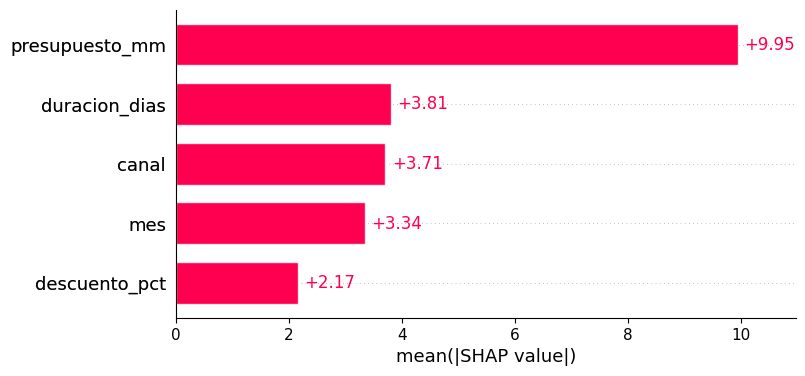

In [21]:
shap.plots.bar(valores_shap)

**Lectura global:** el largo de cada barra es cuánto mueve esa variable la predicción, en promedio
(millones de pesos). ¿Coincide con lo que vimos en el EDA?

{'mes': 3, 'canal': 'Redes sociales', 'presupuesto_mm': 21.1, 'duracion_dias': 9.0, 'descuento_pct': 0} · venta real: 18.4


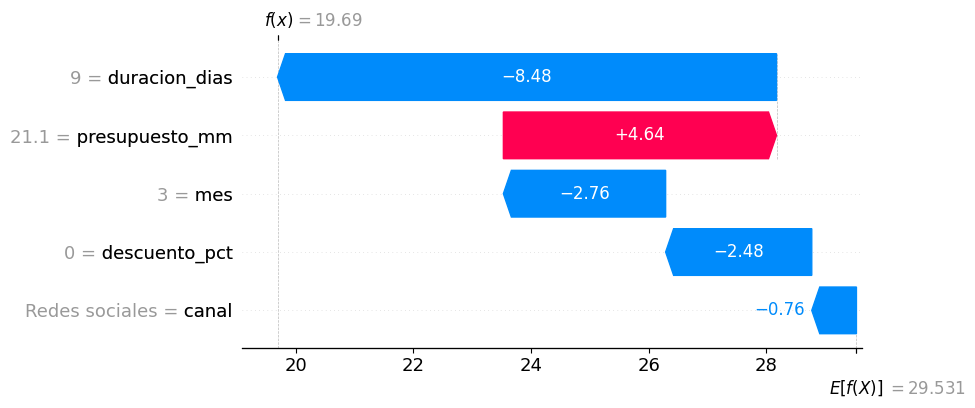

In [22]:
caso = 0  # primera campaña del holdout
print(experimento.X_test.iloc[caso].to_dict(), '· venta real:', experimento.y_test.iloc[caso])
shap.plots.waterfall(valores_shap[caso])

**Lectura local:** se lee de abajo hacia arriba. Parte en `E[f(X)]`, la venta **promedio** del
entrenamiento; cada barra suma (rojo) o resta (azul) según los datos de **esta** campaña, hasta llegar
a su predicción `f(x)`. Así se le explica a la gerencia por qué el modelo estima esa cifra.

**Ojo:** SHAP explica **al modelo**, no al mundo. Que una variable pese mucho dice que el modelo la usa,
no que cambiarla cause más ventas.

**Prompt guiado para hacer este paso con Gemini**

Copien el prompt y péguenlo en Gemini, dentro de Colab. Lean el código que proponga antes de ejecutarlo y compárenlo con la solución de arriba.

```text
Contexto:
Estoy aprendiendo machine learning con PyCaret 4.0.0a8 en Google Colab.

Datos:
Tengo un modelo de regresión de PyCaret 4 en modelo_elegido (un pipeline: preparación de los datos + gradient boosting) y el experimento en experimento. Las campañas del holdout están en experimento.X_test.

Tarea:
Quiero explicar el modelo con SHAP:
1. Un gráfico de barras con la importancia global de las variables.
2. Un gráfico waterfall para la primera campaña del holdout.

Explícame cómo leer cada gráfico para presentárselo a una persona de negocios.

Restricciones:
- Usa la API de PyCaret 4.0.0a8 (from pycaret.tasks import RegressionExperiment). No uses setup() ni from pycaret.regression import *, que son de PyCaret 3, y no instales otra versión.
- No uses plot_model(plot='shap_beeswarm'): en esta versión falla con columnas de texto. Usa la librería shap directamente.
- Separa preparacion = modelo_elegido[:-1] y modelo = modelo_elegido[-1], y usa shap.TreeExplainer(modelo) sobre preparacion.transform(experimento.X_test).
- Asigna feature_names con preparacion.get_feature_names_out() y display_data con los valores originales de experimento.X_test, para que los gráficos se lean bien.
- Una celda corta por paso, sin funciones auxiliares.
- Explica cada línea en español sencillo.
```

## Paso 10 · Guardar el modelo

Antes de guardar, `finalize_model` **reentrena con todos los datos** (entrenamiento + holdout): ya
validamos, así que ahora aprovechamos todas las campañas. Guardamos el *pipeline* completo: la
preparación viaja adentro.

In [23]:
modelo_finalizado = experimento.finalize_model(modelo_elegido)
experimento.save_model(modelo_finalizado.pipeline, 'modelo_campanas')

modelo_cargado = experimento.load_model('modelo_campanas')   # así lo abriría otra persona, otro día

## Paso 11 · Usar el modelo para decidir

La gerencia propone cinco campañas para el próximo trimestre. Todas duran 30 días con 10 % de
descuento; cambian el canal, el mes y el presupuesto. Le damos al modelo los datos **crudos**, tal como
los escribiría la gerencia.

In [24]:
campanas_nuevas = pd.DataFrame({
    'mes':            [3, 3, 12, 12, 12],
    'canal':          ['Redes sociales', 'Buscadores', 'Buscadores', 'Buscadores', 'Buscadores'],
    'presupuesto_mm': [20, 20, 20, 40, 150],
    'duracion_dias':  [30] * 5,
    'descuento_pct':  [10] * 5,
}, index=['A · Redes, marzo', 'B · Buscadores, marzo', 'C · Buscadores, diciembre',
          'D · como C, doble presupuesto', 'E · como C, 150 millones'])

campanas_nuevas['ventas_estimadas_mm'] = modelo_cargado.predict(campanas_nuevas).round(1)
campanas_nuevas['ventas_por_millon'] = (campanas_nuevas['ventas_estimadas_mm']
                                        / campanas_nuevas['presupuesto_mm']).round(2)
campanas_nuevas

,mes,canal,presupuesto_mm,duracion_dias,descuento_pct,ventas_estimadas_mm,ventas_por_millon
"A · Redes, marzo",3,Redes sociales,20,30,10,33.4,1.67
"B · Buscadores, marzo",3,Buscadores,20,30,10,43.9,2.19
"C · Buscadores, diciembre",12,Buscadores,20,30,10,67.1,3.35
"D · como C, doble presupuesto",12,Buscadores,40,30,10,112.1,2.80
"E · como C, 150 millones",12,Buscadores,150,30,10,123.1,0.82


**Preguntas para el curso:**

1. **A contra B:** con el mismo presupuesto y el mismo mes, ¿qué canal conviene?
2. **B contra C:** ¿cuánto pesa la temporada?
3. **C contra D:** al **doblar** el presupuesto, ¿se doblan las ventas? Miren `ventas_por_millon`:
   cada millón extra rinde menos.
4. **E:** el historial no tiene campañas de 150 millones (el máximo está bastante más abajo). El
   modelo de árboles **no extrapola**: repite lo que vio en las campañas más grandes. Esa cifra no es
   una predicción confiable, es una **pregunta para el negocio**. Un modelo solo responde dentro del
   rango de los datos con que aprendió.

In [25]:
print('Presupuesto máximo en el historial:', campanas['presupuesto_mm'].max(), 'millones')

Presupuesto máximo en el historial: 77.4 millones


## Síntesis

1. **EDA** antes de modelar: detectamos faltantes, la cola larga del target, los rendimientos
   decrecientes y una columna sospechosa.
2. **Selección de variables**: por criterio (fuga de datos, identificadores) y con evidencia (comparar
   versiones con la misma validación). La selección automática es una heurística, no un veredicto.
3. **Benchmark → tuning → comparación**: decidimos en validación cruzada; el *tuning* afina décimas.
4. **Holdout**: el examen final, una sola vez, para saber si la estimación fue honesta.
5. **SHAP**: explica qué usa el modelo, global y caso a caso; no demuestra causas.
6. **Guardar y usar**: el *pipeline* recibe datos crudos; sus predicciones valen dentro del rango del
   historial.

**Para repetir este flujo con otro caso** pueden apoyarse en el
[generador de prompts para Gemini](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/prompts-gemini.html).

## Atribución de datos

**Historial de campañas de marketing** (`campanas.csv`)

**Creador:** Equipo docente del módulo.
**Procedencia:** Datos generados con [`gen_campanas.py`](../../../scripts/gen_campanas.py), con semilla fija.
**Nota:** Datos sintéticos; no representan a una organización ni a campañas reales.
**Modificación:** ninguna posterior a la generación; las columnas `clics_mil` (fuga de datos),
`dia_lanzamiento` y `num_creatividades` (sin efecto) y los faltantes de `duracion_dias` se incluyen a
propósito para el ejercicio.